# Digital images

## Colors on a screen

There are many different ways of representing color on a screen, and the RGB format is very prevalent. In this format, color is specified by 3 numbers: the amount of red, green, and blue. This value is an integer and the minimal value is always 0. The maximum value depends on the bit-depth of the image. For 8-bit images, the maximum is 
$$
2^8 - 1 = 256 - 1 = 255
$$
where the 1 is subtracted due to counting starting at zero.

So for our purposes, a color is 3 numbers between 0 and 255: (#red,#green,#blue).

So what color is $(0,0,0)$?

$$(255,255,255)$$

$$(0,255,0)$$

$$(255,255,0)$$

$$(0,255,255)$$

$$(255,0,255)$$

$$(255,128,0)$$

## Images

So images are made up of pixels - in fact, an $array$ of pixels.

And each pixel is 3 numbers between 0 and 255: (r,g,b)

That's it!
\
\
So now need a 3D array: a 2D for red, a 2D for green, a 2D for blue

In [14]:
Nwidth = 800
Nheight = 600

img_array = np.zeros((Nheight,Nwidth,3),dtype=np.uint8)

# Writing image files from code

## Tools and helpers

In [15]:
import numpy as np
from PIL import Image as PILimg
from IPython.display import Image, display
from IPython.display import Audio

def f_displayimage(img_array, ISenlarge):
    image_new = PILimg.fromarray(img_array, mode='RGB')
    image_new.save("image_new_test.jpg")
    #display(Image(filename='./image.jpg', embed=True))
    if ISenlarge:
        big_img = f_enlargeimage(image_new)
        display(big_img)
    else:
        display(image_new)
    #display(Image(filename='./'+big_img, embed=True)

def f_enlargeimage(img):
    mult = 50
    new_size = (img.width * mult, img.height * mult)
    # Resize using NEAREST neighbor interpolation to keep pixels sharp
    rescaled_img = img.resize(new_size, PILimg.NEAREST)
    return rescaled_img    

## 1D image
Let's start easy with a one row image.

In [26]:
INDred = 0
INDgreen = 1
INDblue = 2

In [27]:
Ncol = 10
Nrow = 1

img_array = np.zeros((1,Ncol,3),dtype=np.uint8)

for indcol in range(0,Ncol):
    this_r = int(indcol*255/Ncol)
    img_array[0,indcol,INDred] = this_r
    img_array[0,indcol,INDgreen] = 0
    img_array[0,indcol,INDblue] = 0
    
f_displayimage(img_array,False)

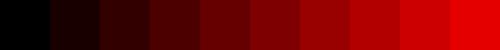

In [33]:
Ncol = 10
Nrow = 1

img_array = np.zeros((1,Ncol,3),dtype=np.uint8)

for icol in range(0,Ncol):
    this_r = int(icol*255/Ncol)
    img_array[0,icol,INDred] = this_r
    img_array[0,icol,INDgreen] = 0
    img_array[0,icol,INDblue] = 0
    
f_displayimage(img_array,True)

## 2D
Now let's do full 2D:

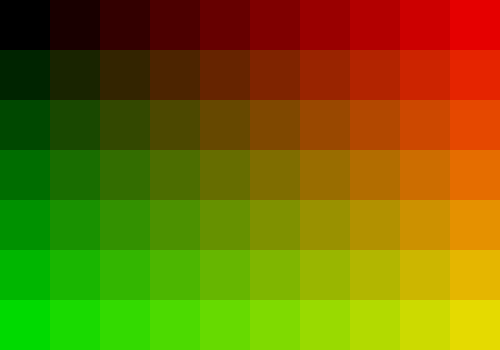

In [34]:
Ncol = 10
Nrow = 7

img_array = np.zeros((Nrow,Ncol,3),dtype=np.uint8)

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        this_r = int(indcol*255/Ncol)
        this_g = int(indrow*255/Nrow)
        img_array[indrow,indcol,INDred] = this_r
        img_array[indrow,indcol,INDgreen] = this_g
        img_array[indrow,indcol,INDblue] = 0

f_displayimage(img_array,True)

## More complicated

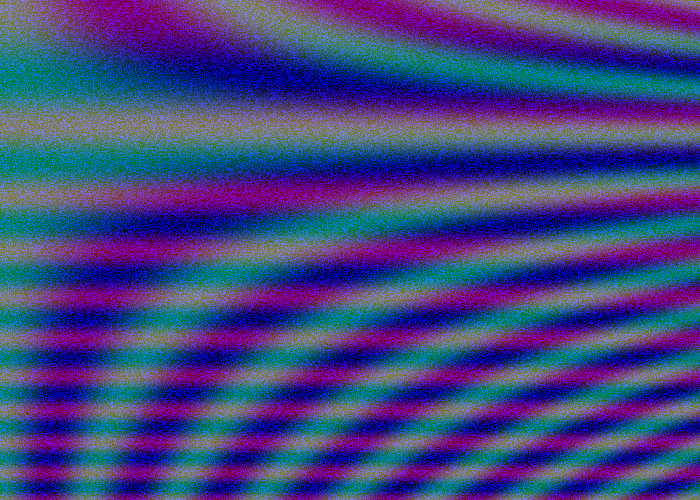

In [35]:
import random

rgbmax = 128
freq0 = 2*np.pi*2
freq1 = 2*np.pi*3

Ncol = 700
Nrow = 500

img_array = np.zeros((Nrow,Ncol,3),dtype=np.uint8)

indtot = 0
for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):

        this_r = random.randint(0,255)
        this_g = random.randint(0,255)
        this_b = random.randint(0,255)
        #this_b = 0

        this_r = int( (np.cos( indrow*(freq0+indtot/(Ncol*10))/Nrow ) + 1)/2.0 * rgbmax )
        this_g = int( (np.cos( indcol*(freq1-indtot/(Nrow*10))/Ncol ) + 1)/2.0 * rgbmax )
        
        img_array[indrow,indcol,INDred] = this_r
        img_array[indrow,indcol,INDgreen] = this_g
        img_array[indrow,indcol,INDblue] = this_b

        indtot += 1

f_displayimage(img_array,False)
